# Setting

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import itertools
import math
from tqdm import tqdm

curfolder = os.getcwd()
print(curfolder)

mtfolder = os.path.join(curfolder, 'Output_TimeSeries')
print(mtfolder)

processedfolder = os.path.join(curfolder, 'TS_processed')
vidfolder = os.path.join(curfolder, 'Output_Videos')

# get all the files in the folder
bodyfiles = glob.glob(os.path.join(mtfolder, '*body_world.csv'))
#handfiles = glob.glob(os.path.join(mtfolder, '*hands_world.csv'))

print(bodyfiles)

vidfiles = glob.glob(os.path.join(vidfolder, '*.mp4'))
#print(vidfiles)

e:\GtST_FLESH_KinTrajectory
e:\GtST_FLESH_KinTrajectory\Output_TimeSeries
['e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\flipped_IP06_02_ABHOLEN.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\GP02_AFFE.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\flipped_IP06_02_ABLEHNEN.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\GP02_ANFANG.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\GP02_ANGELN.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\GP02_ATEM.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\GP02_BART.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\flipped_IP06_02_AFFE.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\GP02_BETEN.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\GP02_BRIEF.mp4_body_world.csv', 'e:\\GtST_FLESH_KinTrajectory\\Output_TimeSeries\\flipped_IP06_02_AKK

# First quality check (body)

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation
from IPython.display import Video

# Load CSV file
outputcsv = glob.glob(os.path.join(mtfolder, '*.csv'))  # Ensure outtputf_ts is defined
files = [x for x in outputcsv if 'GtST' in x]
files = [x for x in files if 'body_world' in x]
fileexample = files[1]
MT_tracking = pd.read_csv(fileexample)

# Create a figure and axis
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Define the number of frames
num_frames = len(MT_tracking)

# Define the scatter plot
scatter = ax.scatter([], [], [], marker='o')

# Update function for animation
def update(frame):
    ax.clear()
    ax.set_xlabel('X Label')
    ax.set_ylabel('Z Label')
    ax.set_zlabel('Y Label')
    ax.set_title('3D Animation')
    
    # Set the limits of the axes based on the maximum values
    ax.set_xlim3d(0, 1)
    ax.set_ylim3d(20, 0)
    ax.set_zlim3d(0, 1) #we need to flip the vertical
    
    # Plot the data for the current frame
    frame_data = MT_tracking.iloc[frame]
    frame_data_body = MT_tracking.iloc[frame]
    x = frame_data.filter(like='X_')
    x_body = frame_data_body.filter(like='X_')
    y = frame_data.filter(like='Z_')
    y_body = frame_data_body.filter(like='Z_')
    z = frame_data.filter(like='Y_')
    z_body = frame_data_body.filter(like='Y_')
    # create scatter that has body in blue, and hands in red
    #scatter = ax.scatter(x, y, z, color='blue')
    scatter = ax.scatter(x_body, y_body, z_body*-1, color='red')

    return scatter

# Create the animation
ani = FuncAnimation(fig, update, frames=num_frames, interval=1000/30)

# Close the figure to prevent displaying the first frame
plt.close(fig)

# Save the animation as a video
ani.save('3D_animation_check.mp4', writer='ffmpeg')

# Display the animation
video_path = '3D_animation_check.mp4'
Video(video_path, embed=True, width=800)

# Preps for processing - one file example

## Clean the data

In [2]:

file = bodyfiles[0]
print(file)

e:\GtST_FLESH_KinTrajectory\Output_TimeSeries\flipped_IP06_02_ABHOLEN.mp4_body_world.csv


In [3]:
problematic_vis = []


def longest_low_visibility_gap(vis_series, threshold=0.5):
    low_vis = (vis_series < threshold).astype(int)
    return max((sum(1 for _ in group) for val, group in itertools.groupby(low_vis) if val == 1), default=0)

def check_visibility_quality(df, keypoint, threshold=0.5, max_gap_len=15, max_low_ratio=0.3):
    vis_cols = [col for col in df.columns if keypoint in col and 'visibility' in col]
    if not vis_cols:
        return None  # No such keypoint found

    vis_series = df[vis_cols[0]]  # Only one column per keypoint
    low_ratio = (vis_series < threshold).mean()
    longest_gap = longest_low_visibility_gap(vis_series, threshold)

    is_flagged = (low_ratio > max_low_ratio) or (longest_gap > max_gap_len)
    return {
        "keypoint": keypoint,
        "low_ratio": low_ratio,
        "longest_gap": longest_gap,
        "flagged": is_flagged
    }

def check_for_visibility_string(df):
    for col in df.columns:
        if 'visibility' in col:
            return True
    return False

# get the last part of the path in sample
def clean_data(file, problems_list, no_vis):
    sample = pd.read_csv(file)
    fileID = os.path.basename(file)

    # replace _body.csv with ''
    fileID = fileID.replace('.mp4', '')
    fileID = fileID.replace('.csv', '')
    #print(fileID)

    # for this purpose we also don't need anything from hip lower
    todel = ['KNEE', 'ANKLE', 'FOOT', 'MOUTH', 'EYE', 'EAR']

    # get rid of all columns that contain the words from todel
    sample = sample.drop([col for col in sample.columns if any(x in col for x in todel)], axis=1)

    # add fileID column to the sample
    sample['fileID'] = fileID

    # Check each of the four keypoints separately
    keypoints = ['RIGHT_WRIST', 'LEFT_WRIST', 'RIGHT_ELBOW', 'LEFT_ELBOW']
    vis_results = {}

    # If there is no col for visibility, append it to no_vis list
    if not check_for_visibility_string(sample):
        no_vis.append(fileID)
        print(f"⚠️ No visibility column found for {fileID}.")
        return sample, problems_list, no_vis
        
    
    else:
        for kp in keypoints:
            result = check_visibility_quality(sample, keypoint=kp)
            if result:
                vis_results[kp] = result
                if result['flagged']:
                    if result['low_ratio'] > 0.3 and result['longest_gap'] > 25:
                        problems_list.append(fileID)
                        print(f"⚠️ {kp}: Low visibility detected — "
                            f"{result['low_ratio']*100:.1f}% low frames, "
                            f"max gap = {result['longest_gap']} frames.")

        # for body - lowbody columns
        lowbody = ['FOOT', 'HEEL', 'ANKLE', 'KEE']
        sample = sample.drop([col for col in sample.columns if any(x in col for x in lowbody)], axis=1)


    return sample, problems_list, no_vis

missing_vis = []
sample, problematic_vis, missing_vis = clean_data(file, problematic_vis, missing_vis)

# % low frames - The proportion of frames in the video/trial where the visibility value for a keypoint was below a certain threshold, typically indicating the keypoint was not reliably detected.



## Flip the Y axis vertical data

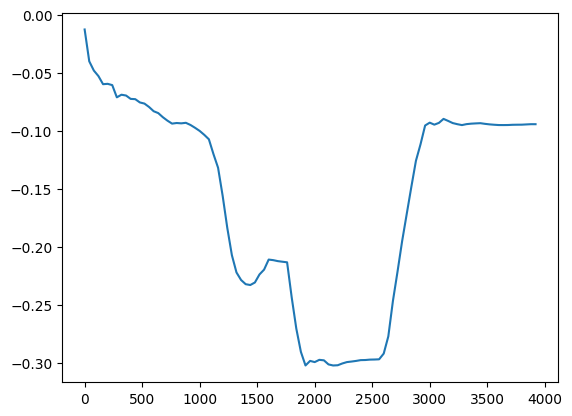

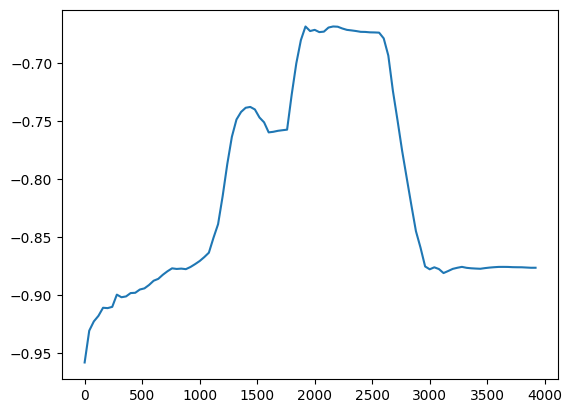

In [4]:
# plot left wrist, vertical (pre flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

# flip the y-axis data (code modified from envisionbox)
def flip_data(df):
    df = df.copy()  # avoid modifying original dataframe directly
    cols = [col for col in df.columns if 'Y_' in col]

    # Get max y-value from the first frame
    maxpoint = max(df.loc[0, cols])

    # Flip all Y_ columns across all rows
    for joint in cols:
        df.loc[:, joint] = maxpoint - df[joint] - 1

    return df

sample = flip_data(sample)

# plot left wrist, vertical (post flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

## Interpolate the data

In [5]:
# obtain column names
def interpolate(sample):
    cols = sample.columns
    #print(cols)

# put away time and fileID from cols
    cols = cols.drop(['time', 'fileID'])

# loop over the cols and interpolate missing data
    for col in cols:
        sample[col] = sample[col].interpolate(method='linear', x = sample['time'], limit=10)
    return cols, sample

cols, sample = interpolate(sample)

## Smooth the data

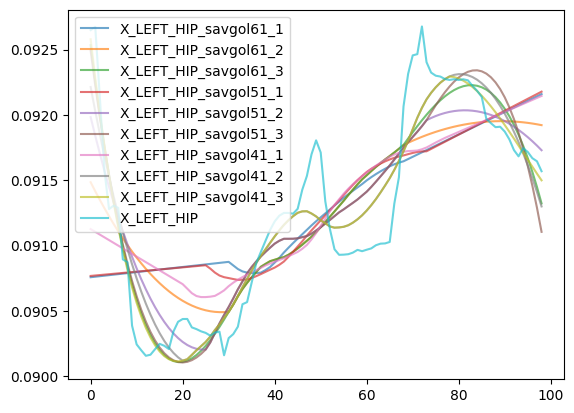

In [6]:
# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'X_LEFT_HIP'
z = 'Z_LEFT_HIP'
y = 'Y_LEFT_HIP'


# list possible window
#window = [21, 19, 15, 11]
window = [61, 51, 41]
# list possible orders
order = [1, 2, 3]

# col of interest
samplecol = [y, z, x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
LKnee_y = sample[y].tolist()
LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
df_smooth[y] = LKnee_y
df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
plt.show()




We will use savgol 15,3 for upper body,

and 41, 3 for lower body (here only hip). We will not need it anyway (unless we want to normalize something), but it seems like there is lot of measurement error due to the sitting posture so strong filter is needed

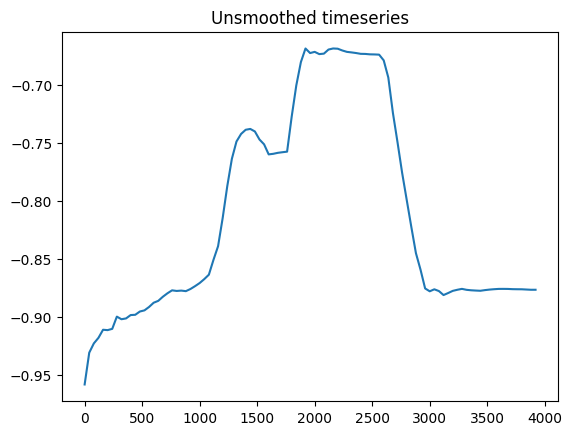

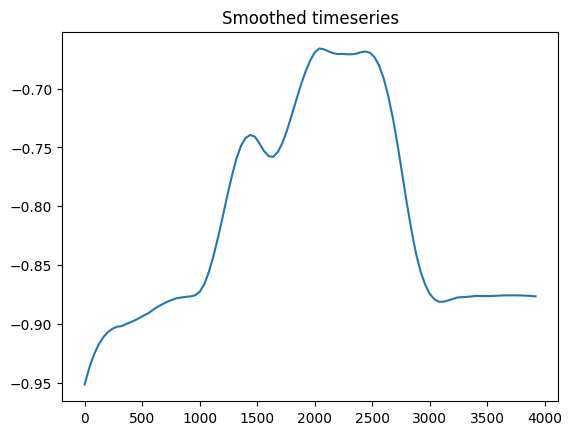

In [7]:
# obtain separate lists of the columns for the upper and lower body (face is included in upper body)

def smooth_data(sample):
    
    if 'body' in sample['fileID'][0]:

        cols_upperbody = ['X_NOSE', 'Y_NOSE', 'Z_NOSE', 'X_LEFT_SHOULDER', 'Y_LEFT_SHOULDER', 'Z_LEFT_SHOULDER', 'X_RIGHT_SHOULDER', 'Y_RIGHT_SHOULDER', 'Z_RIGHT_SHOULDER', 'X_LEFT_ELBOW', 'Y_LEFT_ELBOW', 'Z_LEFT_ELBOW', 'X_RIGHT_ELBOW', 'Y_RIGHT_ELBOW', 'Z_RIGHT_ELBOW', 'X_LEFT_WRIST', 'Y_LEFT_WRIST', 'Z_LEFT_WRIST', 'X_RIGHT_WRIST', 'Y_RIGHT_WRIST', 'Z_RIGHT_WRIST', 'X_LEFT_PINKY', 'Y_LEFT_PINKY', 'Z_LEFT_PINKY', 'X_RIGHT_PINKY', 'Y_RIGHT_PINKY', 'Z_RIGHT_PINKY', 'X_LEFT_INDEX', 'Y_LEFT_INDEX', 'Z_LEFT_INDEX', 'X_RIGHT_INDEX', 'Y_RIGHT_INDEX', 'Z_RIGHT_INDEX', 'X_LEFT_THUMB', 'Y_LEFT_THUMB', 'Z_LEFT_THUMB', 'X_RIGHT_THUMB', 'Y_RIGHT_THUMB']
        cols_lowerbody = ['X_LEFT_HIP', 'Y_LEFT_HIP', 'Z_LEFT_HIP', 'X_RIGHT_HIP', 'Y_RIGHT_HIP', 'Z_RIGHT_HIP']

        # smooth upperbody and face with savgol 20,4                            
        for col in cols_upperbody:
            sample[col] = scipy.signal.savgol_filter(sample[col], 15, 3)
        
        # smooth lowerbod with savgol 30,3
        for col in cols_lowerbody:  
            sample[col] = scipy.signal.savgol_filter(sample[col], 41, 3)

    elif 'hands' in sample['fileID'][0]:
        hand_cols = sample.columns
        # get rid of time and fileID
        hand_cols = hand_cols.drop(['time', 'fileID'])
        # smooth hand with savgol 20,4                                             
        for col in hand_cols:
            sample[col] = scipy.signal.savgol_filter(sample[col], 21, 4)
    
    return(sample)


plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.title('Unsmoothed timeseries')
plt.show()

sample = smooth_data(sample)

# plot the smoothed data
plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.title('Smoothed timeseries')
plt.show()

# Center all keypoints

We want to center so that middle of torso is always [0,0,0]

In [9]:
import pandas as pd

def add_mid_torso_and_center_df(
    df,
    l_shoulder_prefix="LEFT_SHOULDER",
    r_shoulder_prefix="RIGHT_SHOULDER",
    l_hip_prefix="LEFT_HIP",
    r_hip_prefix="RIGHT_HIP",
    time_col="time"
):
    """
    Create mid-torso from shoulders and hips and center all XYZ keypoints on it.

    Expected columns:
      X_<name>, Y_<name>, Z_<name>, visibility_<name>

    Returns a new DataFrame with:
      - X_midTorso, Y_midTorso, Z_midTorso added
      - All X_*, Y_*, Z_* centered on mid-torso
      - visibility_* and time unchanged
    """

    df = df.copy()

    # --- 1. Compute midpoints ---
    df["X_midTorso"] = 0.5 * (df[f"X_{l_shoulder_prefix}"] + df[f"X_{r_shoulder_prefix}"])
    df["Y_midTorso"] = 0.5 * (df[f"Y_{l_shoulder_prefix}"] + df[f"Y_{r_shoulder_prefix}"])
    df["Z_midTorso"] = 0.5 * (df[f"Z_{l_shoulder_prefix}"] + df[f"Z_{r_shoulder_prefix}"])

    hips_mid_x = 0.5 * (df[f"X_{l_hip_prefix}"] + df[f"X_{r_hip_prefix}"])
    hips_mid_y = 0.5 * (df[f"Y_{l_hip_prefix}"] + df[f"Y_{r_hip_prefix}"])
    hips_mid_z = 0.5 * (df[f"Z_{l_hip_prefix}"] + df[f"Z_{r_hip_prefix}"])

    df["X_midTorso"] = 0.5 * (df["X_midTorso"] + hips_mid_x)
    df["Y_midTorso"] = 0.5 * (df["Y_midTorso"] + hips_mid_y)
    df["Z_midTorso"] = 0.5 * (df["Z_midTorso"] + hips_mid_z)

    # --- 2. Center all XYZ columns on mid-torso ---
    x_cols = [c for c in df.columns if c.startswith("X_")]
    y_cols = [c for c in df.columns if c.startswith("Y_")]
    z_cols = [c for c in df.columns if c.startswith("Z_")]

    for c in x_cols:
        df[c] = df[c] - df["X_midTorso"]
    for c in y_cols:
        df[c] = df[c] - df["Y_midTorso"]
    for c in z_cols:
        df[c] = df[c] - df["Z_midTorso"]

    return df


# usage on sample
sample = add_mid_torso_and_center_df(sample)

# check that mid-torso is now at (0,0,0)
print(sample[["X_midTorso", "Y_midTorso", "Z_midTorso"]].head())


   X_midTorso  Y_midTorso  Z_midTorso
0         0.0         0.0         0.0
1         0.0         0.0         0.0
2         0.0         0.0         0.0
3         0.0         0.0         0.0
4         0.0         0.0         0.0


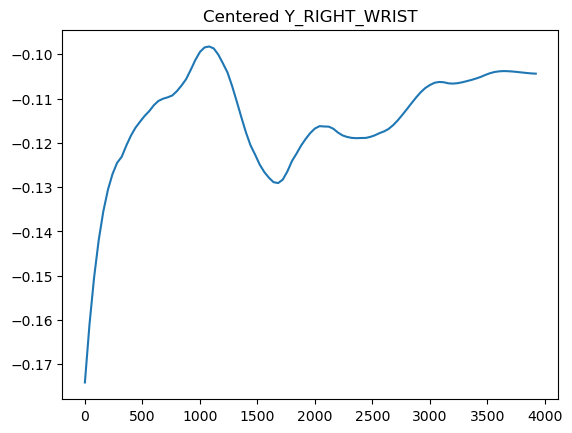

In [135]:
# plot RWRIST
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.title('Centered Y_RIGHT_WRIST')
plt.show()

# Normalize by trunk length

No trunk length provided, computing from data...
Trunk length used for normalization: 0.4801785136110156


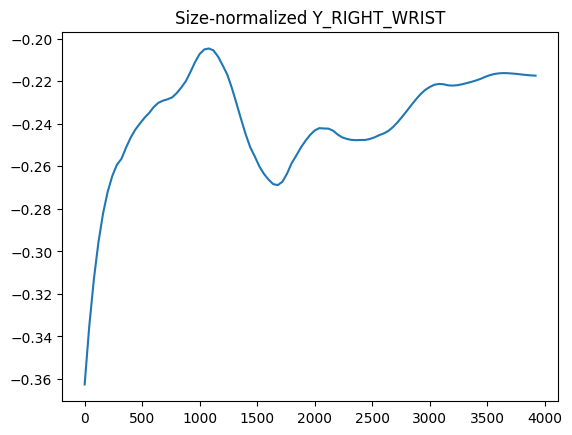

In [10]:
def size_normalize_by_trunk(df, trunk_len=None):

    if trunk_len is None:

        print("No trunk length provided, computing from data...")
    
        # create mid shoulder
        df["X_midShoulder"] = 0.5 * (df["X_LEFT_SHOULDER"] + df["X_RIGHT_SHOULDER"])
        df["Y_midShoulder"] = 0.5 * (df["Y_LEFT_SHOULDER"] + df["Y_RIGHT_SHOULDER"])
        df["Z_midShoulder"] = 0.5 * (df["Z_LEFT_SHOULDER"] + df["Z_RIGHT_SHOULDER"])

        # create midhip
        df["X_midHip"] = 0.5 * (df["X_LEFT_HIP"] + df["X_RIGHT_HIP"])
        df["Y_midHip"] = 0.5 * (df["Y_LEFT_HIP"] + df["Y_RIGHT_HIP"])
        df["Z_midHip"] = 0.5 * (df["Z_LEFT_HIP"] + df["Z_RIGHT_HIP"])

        # compute trunk length as median distance between mid-shoulder and mid-hip
        dx = df["X_midShoulder"] - df["X_midHip"]
        dy = df["Y_midShoulder"] - df["Y_midHip"]
        dz = df["Z_midShoulder"] - df["Z_midHip"]

        trunk_len = np.median(np.sqrt(dx**2 + dy**2 + dz**2))

    else:
        print(f"Using provided trunk length: {trunk_len}") 

    xyz_cols = [c for c in df.columns if c.startswith(("X_", "Y_", "Z_"))]
    for c in xyz_cols:
        df[c] = df[c] / trunk_len

    return trunk_len, df

trunk_len, sample = size_normalize_by_trunk(sample)
print(f"Trunk length used for normalization: {trunk_len}")

# plot y_right_wrist again
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.title('Size-normalized Y_RIGHT_WRIST')
plt.show()




## Derive Speed and Smooth

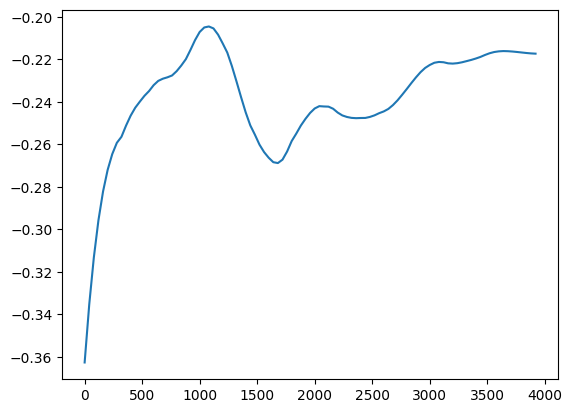

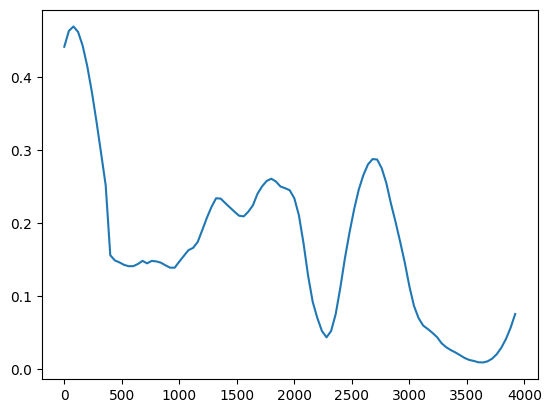

In [11]:
def derive_speed_smooth(cols, sample, sr):
    speedcols = [col.replace('Y_', '').replace('X_', '').replace('Z_', '') for col in cols]
    speedcols = [col.replace('PINKF', 'PINKY_F').replace('INDEF', 'INDEX_F') for col in speedcols]
    speedcols = list(set(speedcols))  # keep only unique values

    # Get rid of all columns with visibility
    speedcols = [col for col in speedcols if 'visibility' not in col]

    speed_dict = {}

    for col in speedcols:
        try:
            x = sample['X_' + col].to_numpy()
            y = sample['Y_' + col].to_numpy()
            z = sample['Z_' + col].to_numpy()

            speed = np.insert(np.sqrt(np.diff(x)**2 + np.diff(y)**2 + np.diff(z)**2), 0, 0)
            speed = np.abs(speed)
            speed = scipy.signal.savgol_filter(speed, 20, 3)
            speed = speed * sr  # convert to units per second

            speed_dict[col + '_speed'] = speed
        except KeyError:
            print(f"Skipping {col}: missing data")
            continue

    # Add all new speed columns at once
    speed_df = pd.DataFrame(speed_dict)
    sample = pd.concat([sample.reset_index(drop=True), speed_df], axis=1)

    return sample


hand_cols = sample.columns
# get rid of time and fileID
hand_cols = hand_cols.drop(['time', 'fileID']) # 'fileID'
# get rid of visibility cols
hand_cols = hand_cols.drop([col for col in hand_cols if 'visibility' in col])

sample = derive_speed_smooth(hand_cols, sample, sr=30.0)

# plot RIGHT_WRIST_speed
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['RIGHT_WRIST_speed'])
plt.show()

## Derive vertical velocity and smooth

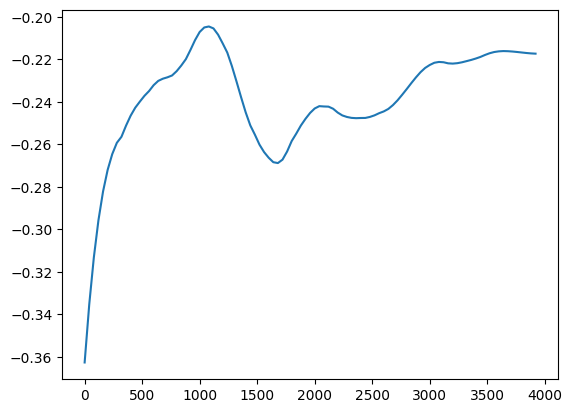

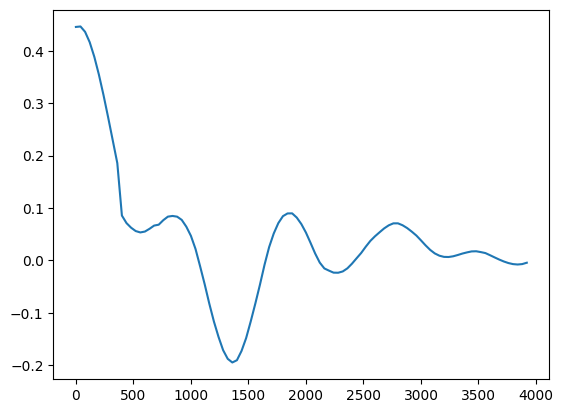

In [12]:
def derive_vertical_vel_smooth(sample, sr):
    verticalcols = [col for col in sample.columns if 'Y_' in col and 'speed' not in col]
    new_vel_cols = {}

    for col in verticalcols:
        velocity = np.insert(np.diff(sample[col]), 0, 0)
        velocity = scipy.signal.savgol_filter(velocity, 20, 3)
        new_vel_cols[col + '_velocity'] = velocity
        # get to units per second
        new_vel_cols[col + '_velocity'] = new_vel_cols[col + '_velocity'] * sr

    sample = pd.concat([sample, pd.DataFrame(new_vel_cols, index=sample.index)], axis=1)
    return sample

sr= 30
sample = derive_vertical_vel_smooth(sample, sr)

plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['Y_RIGHT_WRIST_velocity'])
plt.show()

## Derive Acceleration and Smooth

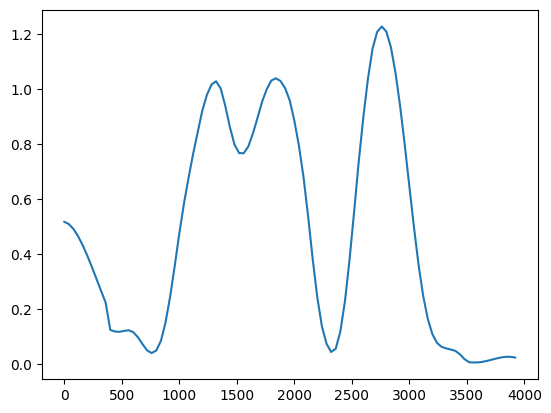

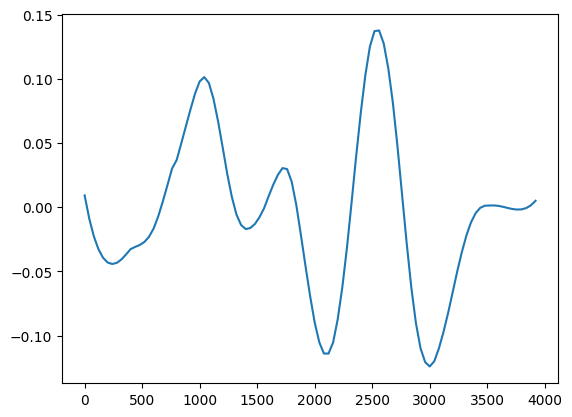

In [13]:
def derive_accel_smooth(speedcols, sample):

    new_accel_cols = {}

    for col in speedcols:
        newcolname = col.replace('speed', 'acceleration')
        accel = np.insert(np.diff(sample[col]), 0, 0)
        accel = scipy.signal.savgol_filter(accel, 20, 3)
        new_accel_cols[newcolname] = accel

    # Efficiently add all acceleration columns at once
    sample = pd.concat([sample, pd.DataFrame(new_accel_cols, index=sample.index)], axis=1)
    return sample

speedcols = [col for col in sample.columns if 'speed' in col]
sample = derive_accel_smooth(speedcols, sample)

plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
    

## Derive Jerk and Smooth

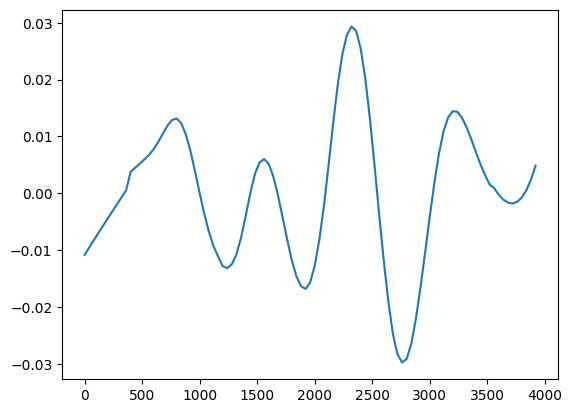

In [14]:
def derive_jerk_smooth(sample):

    # Find acceleration columns
    accols = [col for col in sample.columns if '_acceleration' in col]

    new_jerk_cols = {}

    for col in accols:
        newcolname = col.replace('acceleration', 'jerk')
        jerk = np.insert(np.diff(sample[col]), 0, 0)
        jerk = scipy.signal.savgol_filter(jerk, 20, 3)
        new_jerk_cols[newcolname] = jerk

    # Efficiently concatenate all new jerk columns
    sample = pd.concat([sample, pd.DataFrame(new_jerk_cols, index=sample.index)], axis=1)
    return sample

accols = [col for col in sample.columns if 'acceleration' in col]
sample = derive_jerk_smooth(sample)
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()


## Plotting all the derivations

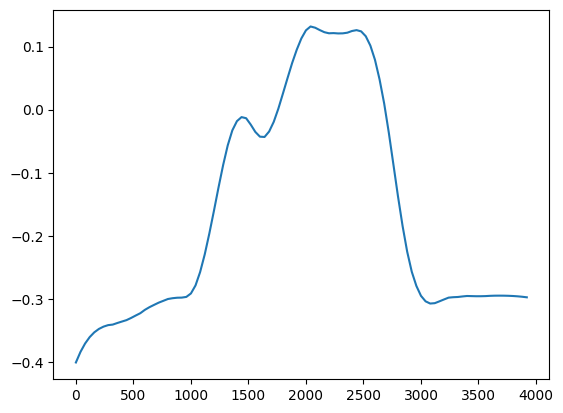

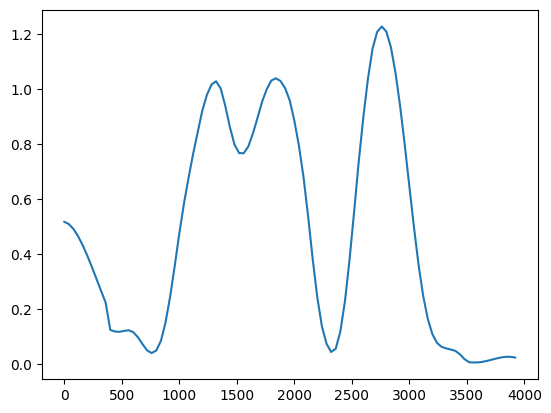

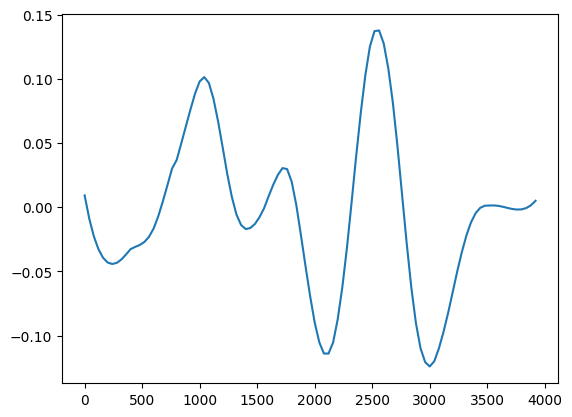

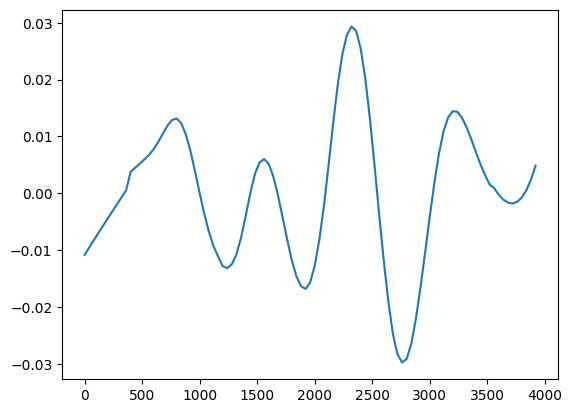

In [15]:

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()

# Loop to calculate trunk length per each file

In [16]:
# check if median_trunk_length_per_pcn.csv already exists, if not, create it

if not os.path.exists(os.path.join(curfolder, 'median_trunk_length_per_pcn.csv')):
    print("median_trunk_length_per_pcn.csv not found, creating it...")

    error_list = []


    trunk_len_list = []

    # create txt file
    f = open("error_log.txt", "w")

    #for loop to go through every file in the timeseries folder
    for file in bodyfiles:
        print("This is file" + str(file) + "// Count: " + str(bodyfiles.index(file)) + " of " + str(len(bodyfiles)) + " files in total")


        try:
            # Cleaning
            sample, problems_vis, missing_vis = clean_data(file, problems_vis, missing_vis)
            try:
                fileID = sample['fileID'][0]
            except:
                print('fileID not found')
                f.write(f'{fileID} fileID not found\n')
                continue

            sample = flip_data(sample)
            cols, sample = interpolate(sample)
            sample = smooth_data(sample)

            # Add mid-torso and center data on it
            sample = add_mid_torso_and_center_df(sample)
            # Size-normalize by trunk length
            trunk_len, sample = size_normalize_by_trunk(sample)

            # append trunk_len with fileID to trunk_len_list
            trunk_len_list.append((fileID, trunk_len))
        

        except Exception as e:
            print(f"Error processing {file}: {e}")
            error_list.append(file)
            f.write(f'{file} {e}\n')
            continue
            #break

        #break
        
    f.close()

    # make a df out of trunk_len_list
    trunk_len_df = pd.DataFrame(trunk_len_list, columns=['fileID', 'trunk_len'])

    # get rid of all rows where fileID contains flipped
    trunk_len_df = trunk_len_df[~trunk_len_df['fileID'].str.contains('flipped')]
    trunk_len_df = trunk_len_df[~trunk_len_df['fileID'].str.contains('_video_raw')]


    # make a pcn_ID column by taking fiurst element of fileID split by '_'
    trunk_len_df['pcn_ID'] = trunk_len_df['fileID'].apply(lambda x: x.split('_')[0])

    # create a median trunk length per pcn_ID
    median_trunk_len_df = trunk_len_df.groupby('pcn_ID')['trunk_len'].median().reset_index()

    # save it
    median_trunk_len_df.to_csv(os.path.join(curfolder, 'median_trunk_length_per_pcn.csv'), index=False)

    # display
    median_trunk_len_df.head(10)

else:
    print("median_trunk_length_per_pcn.csv already exists, loading it...")
    median_trunk_len_df = pd.read_csv(os.path.join(curfolder, 'median_trunk_length_per_pcn.csv'))
    median_trunk_len_df.head(10)



median_trunk_length_per_pcn.csv already exists, loading it...


In [17]:
median_trunk_len_df.head(10)


,pcn_ID,trunk_len
0,GP01,0.440477
1,GP02,0.433018
2,GP03,0.451161
3,GP04,0.447301
4,GP05,0.424638
5,GP06,0.419394
6,GP08,0.443761
7,GP10,0.453403
8,GP11,0.447790
9,GP14,0.417785


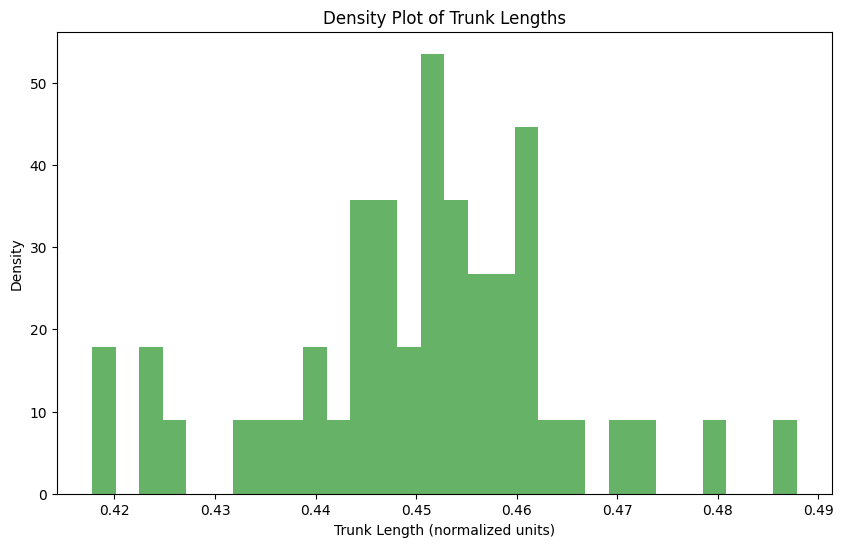

In [19]:
# make a density plot
plt.figure(figsize=(10, 6))
plt.hist(median_trunk_len_df['trunk_len'], bins=30, density=True, alpha=0.6, color='g')
plt.title('Density Plot of Trunk Lengths')
plt.xlabel('Trunk Length (normalized units)')
plt.ylabel('Density')
plt.show()

# Final code to process body files in Output_TimeSeries

In [20]:
error_list = []
problems_vis = []
missing_vis = []

# create txt file
f = open("error_log.txt", "w")

#for loop to go through every file in the timeseries folder
for file in bodyfiles:

    if 'flipped' in file or '_video_raw' in file:
        continue

    fname = os.path.basename(file)
    print("This is file" + str(fname) + "// Count: " + str(bodyfiles.index(file)) + " of " + str(len(bodyfiles)) + " files in total")

    try:
        # Get sampling rate
        if fname.startswith("LP") or fname.startswith("GtST"):
            sr = 30
        else:
            sr = 50
            
        # Cleaning
        sample, problems_vis, missing_vis = clean_data(file, problems_vis, missing_vis)
        try:
            fileID = sample['fileID'][0]
        except:
            print('fileID not found')
            f.write(f'{fileID} fileID not found\n')
            continue

        sample = flip_data(sample)
        cols, sample = interpolate(sample)
        sample = smooth_data(sample)

        # Add mid-torso and center data on it
        sample = add_mid_torso_and_center_df(sample)

        # get pcnID
        pcn_ID = fileID.split('_')[0]
        # get median trunk length for this pcn_ID
        median_trunk_len = median_trunk_len_df[median_trunk_len_df['pcn_ID'] == pcn_ID]['trunk_len'].values[0]
        # Size-normalize by median trunk length for this pcn_ID
        trunk_len, sample = size_normalize_by_trunk(sample, trunk_len=median_trunk_len)

        # convert all to cms
        xyz_cols = [c for c in sample.columns if c.startswith(("X_", "Y_", "Z_"))]
        for c in xyz_cols:
            sample[c] = sample[c] * 100

        # Deriving
        sample = derive_speed_smooth(cols, sample, sr=sr)
        sample = derive_vertical_vel_smooth(sample, sr=sr)
        speedcols = [col for col in sample.columns if 'speed' in col]
        sample = derive_accel_smooth(speedcols, sample)
        sample = derive_jerk_smooth(sample)


        # Normalizing wrist by elbow and elbow by shoulder - speed
        if 'LEFT_WRIST_speed' in sample.columns and 'LEFT_ELBOW_speed' in sample.columns:
            sample['LEFT_WRIST_speed_norm'] = sample['LEFT_WRIST_speed'] - sample['LEFT_ELBOW_speed']
        if 'RIGHT_WRIST_speed' in sample.columns and 'RIGHT_ELBOW_speed' in sample.columns:
            sample['RIGHT_WRIST_speed_norm'] = sample['RIGHT_WRIST_speed'] - sample['RIGHT_ELBOW_speed']
        if 'LEFT_ELBOW_speed' in sample.columns and 'LEFT_SHOULDER_speed' in sample.columns:
            sample['LEFT_ELBOW_speed_norm'] = sample['LEFT_ELBOW_speed'] - sample['LEFT_SHOULDER_speed']
        if 'RIGHT_ELBOW_speed' in sample.columns and 'RIGHT_SHOULDER_speed' in sample.columns:
            sample['RIGHT_ELBOW_speed_norm'] = sample['RIGHT_ELBOW_speed'] - sample['RIGHT_SHOULDER_speed']

        # Normalizing wrist by elbow and elbow by shoulder - acceleration
        if 'LEFT_WRIST_acceleration' in sample.columns and 'LEFT_ELBOW_acceleration' in sample.columns:
            sample['LEFT_WRIST_acceleration_norm'] = sample['LEFT_WRIST_acceleration'] - sample['LEFT_ELBOW_acceleration']
        if 'RIGHT_WRIST_acceleration' in sample.columns and 'RIGHT_ELBOW_acceleration' in sample.columns:
            sample['RIGHT_WRIST_acceleration_norm'] = sample['RIGHT_WRIST_acceleration'] - sample['RIGHT_ELBOW_acceleration']
        if 'LEFT_ELBOW_acceleration' in sample.columns and 'LEFT_SHOULDER_acceleration' in sample.columns:
            sample['LEFT_ELBOW_acceleration_norm'] = sample['LEFT_ELBOW_acceleration'] - sample['LEFT_SHOULDER_acceleration']
        if 'RIGHT_ELBOW_acceleration' in sample.columns and 'RIGHT_SHOULDER_acceleration' in sample.columns:
            sample['RIGHT_ELBOW_acceleration_norm'] = sample['RIGHT_ELBOW_acceleration'] - sample['RIGHT_SHOULDER_acceleration']

        # Normalizing wrist by elbow and elbow by shoulder - jerk
        if 'LEFT_WRIST_jerk' in sample.columns and 'LEFT_ELBOW_jerk' in sample.columns:
            sample['LEFT_WRIST_jerk_norm'] = sample['LEFT_WRIST_jerk'] - sample['LEFT_ELBOW_jerk']
        if 'RIGHT_WRIST_jerk' in sample.columns and 'RIGHT_ELBOW_jerk' in sample.columns:
            sample['RIGHT_WRIST_jerk_norm'] = sample['RIGHT_WRIST_jerk'] - sample['RIGHT_ELBOW_jerk']
        if 'LEFT_ELBOW_jerk' in sample.columns and 'LEFT_SHOULDER_jerk' in sample.columns:
            sample['LEFT_ELBOW_jerk_norm'] = sample['LEFT_ELBOW_jerk'] - sample['LEFT_SHOULDER_jerk']
        if 'RIGHT_ELBOW_jerk' in sample.columns and 'RIGHT_SHOULDER_jerk' in sample.columns:
            sample['RIGHT_ELBOW_jerk_norm'] = sample['RIGHT_ELBOW_jerk'] - sample['RIGHT_SHOULDER_jerk']

        # Now get rid of all visibility columns
        sample = sample.drop([col for col in sample.columns if 'visibility' in col], axis=1)

        # Now I want to create some aggregated columns for arm speed (left+right shoulder, elbow, wrist) and arm angle speed (left+right shoulder, elbow, wrist flex speed) as euclidian distance
        sample['total_arm_speed'] = np.sqrt(
            sample['LEFT_SHOULDER_speed']**2 +
            sample['RIGHT_SHOULDER_speed']**2 +
            sample['LEFT_ELBOW_speed_norm']**2 +
            sample['RIGHT_ELBOW_speed_norm']**2 +
            sample['LEFT_WRIST_speed_norm']**2 +
            sample['RIGHT_WRIST_speed_norm']**2
        )

        # Total arm acceleration
        sample['total_arm_acceleration'] = np.sqrt(
            sample['LEFT_SHOULDER_acceleration']**2 +
            sample['RIGHT_SHOULDER_acceleration']**2 +
            sample['LEFT_ELBOW_acceleration_norm']**2 +
            sample['RIGHT_ELBOW_acceleration_norm']**2 +
            sample['LEFT_WRIST_acceleration_norm']**2 +
            sample['RIGHT_WRIST_acceleration_norm']**2
        )

        # Total arm jerk
        sample['total_arm_jerk'] = np.sqrt(
            sample['LEFT_SHOULDER_jerk']**2 +
            sample['RIGHT_SHOULDER_jerk']**2 +
            sample['LEFT_ELBOW_jerk_norm']**2 +
            sample['RIGHT_ELBOW_jerk_norm']**2 +
            sample['LEFT_WRIST_jerk_norm']**2 +
            sample['RIGHT_WRIST_jerk_norm']**2
        )

        # Distance from torso center/plane
        
        # Keypoints
        LSH = sample[['X_LEFT_SHOULDER',  'Y_LEFT_SHOULDER',  'Z_LEFT_SHOULDER']].values
        RSH = sample[['X_RIGHT_SHOULDER', 'Y_RIGHT_SHOULDER', 'Z_RIGHT_SHOULDER']].values
        LHIP= sample[['X_LEFT_HIP',       'Y_LEFT_HIP',       'Z_LEFT_HIP']].values
        RHIP= sample[['X_RIGHT_HIP',      'Y_RIGHT_HIP',      'Z_RIGHT_HIP']].values
        LW  = sample[['X_LEFT_WRIST',     'Y_LEFT_WRIST',     'Z_LEFT_WRIST']].values
        RW  = sample[['X_RIGHT_WRIST',    'Y_RIGHT_WRIST',    'Z_RIGHT_WRIST']].values

        # Torso plane normal
        n = np.cross(RSH - LSH, RHIP - LSH)

        # Torso centre
        centre = (LSH + RSH + LHIP + RHIP) / 4.0

        # Distances (unsigned)
        lwrist_centre = np.linalg.norm(LW - centre, axis=1)
        rwrist_centre = np.linalg.norm(RW - centre, axis=1)

        # Put distances into dataframe
        sample['lwrist_centre'] = lwrist_centre
        sample['rwrist_centre'] = rwrist_centre

        # Add smoothed torso centre coordinates (optional)
        sample['torsoCentre_X'] = centre[:, 0]
        sample['torsoCentre_Y'] = centre[:, 1]
        sample['torsoCentre_Z'] = centre[:, 2]

        # First and second derivatives (speed and acceleration)
        for label in ['lwrist_centre', 'rwrist_centre']:
            ts = sample[label]
            sample[label + '_speed'] = np.abs(np.insert(np.diff(ts), 0, 0))
            sample[label + '_speed'] = scipy.signal.savgol_filter(sample[label + '_speed'], 15, 3)
            sample[label + '_speed'] = sample[label + '_speed'] * sr  # Convert to units per second
            sample[label + '_acceleration'] = np.insert(np.diff(sample[label + '_speed']), 0, 0)
            sample[label + '_acceleration'] = scipy.signal.savgol_filter(sample[label + '_acceleration'], 15, 3)

        # Save
        globals()[fileID] = sample
        globals()[fileID].to_csv(os.path.join(processedfolder, f'{fileID}.csv'), index=False)

    except Exception as e:
        print(f"Error processing {file}: {e}")
        error_list.append(file)
        f.write(f'{file} {e}\n')
        continue
        #break
    
f.close()




This is fileGP02_AFFE.mp4_body_world.csv// Count: 1 of 12867 files in total
Using provided trunk length: 0.4330183122669266
This is fileGP02_ANFANG.mp4_body_world.csv// Count: 3 of 12867 files in total
Using provided trunk length: 0.4330183122669266
This is fileGP02_ANGELN.mp4_body_world.csv// Count: 4 of 12867 files in total
Using provided trunk length: 0.4330183122669266
This is fileGP02_ATEM.mp4_body_world.csv// Count: 5 of 12867 files in total
Using provided trunk length: 0.4330183122669266
This is fileGP02_BART.mp4_body_world.csv// Count: 6 of 12867 files in total
Using provided trunk length: 0.4330183122669266
This is fileGP02_BETEN.mp4_body_world.csv// Count: 8 of 12867 files in total
Using provided trunk length: 0.4330183122669266
This is fileGP02_BRIEF.mp4_body_world.csv// Count: 9 of 12867 files in total
Using provided trunk length: 0.4330183122669266
This is fileGP02_BUERO.mp4_body_world.csv// Count: 11 of 12867 files in total
Using provided trunk length: 0.4330183122669266


This is how much files have problems with visibility

In [21]:
# Length of the unique instances
problems_vis = list(set(problems_vis))
len(problems_vis)

1928

In [22]:
# Save it
with open('problems_visibility_all.txt', 'w') as f:
    for item in problems_vis:
        f.write("%s\n" % item)